# EDA File

- Answering some business questions realted to the dataset

### **Business Questions to Answer before training**

1. 	Which days of the week sell the most?	
2.	Do SNAP (food-stamp) days increase food sales?	
3.	Which holidays or events raise or lower sales?
4.	Are there monthly or seasonal patterns?	
5.	Do price cuts lead to more units sold?
6.	How different are the 4 stores?
7.	Which departments (FOODS_1/2/3) drive most of the volume?
8.  How predictable are items: steady sellers vs rare sellers?


### Step 1: Load the Parquet file

In [1]:
# Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import seaborn as sns
from pathlib import Path
import yaml

In [2]:
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yaml").exists())

with open(ROOT / "config.yaml") as f:
    cfg = yaml.safe_load(f)

df = pd.read_parquet(ROOT / cfg["paths"]["interim"] / "sales_clean.parquet")
print(df.shape)
(df.head())

(8567581, 21)


,id,item_id,dept_id,cat_id,store_id,state_id,d,sales,date,wm_yr_wk,...,wday,month,year,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,sell_price,is_closed
0,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,d_1,3,2011-01-29,11101,...,1,1,2011,NaN,NaN,NaN,NaN,0,2.0,0
1,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,d_2,0,2011-01-30,11101,...,2,1,2011,NaN,NaN,NaN,NaN,0,2.0,0
2,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,d_3,0,2011-01-31,11101,...,3,1,2011,NaN,NaN,NaN,NaN,0,2.0,0
3,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,d_4,1,2011-02-01,11101,...,4,2,2011,NaN,NaN,NaN,NaN,1,2.0,0
4,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,d_5,4,2011-02-02,11101,...,5,2,2011,NaN,NaN,NaN,NaN,1,2.0,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8567581 entries, 0 to 8567580
Data columns (total 21 columns):
 #   Column        Dtype         
---  ------        -----         
 0   id            str           
 1   item_id       str           
 2   dept_id       str           
 3   cat_id        str           
 4   store_id      str           
 5   state_id      str           
 6   d             str           
 7   sales         int64         
 8   date          datetime64[us]
 9   wm_yr_wk      int64         
 10  weekday       str           
 11  wday          int64         
 12  month         int64         
 13  year          int64         
 14  event_name_1  str           
 15  event_type_1  str           
 16  event_name_2  str           
 17  event_type_2  str           
 18  snap_CA       int64         
 19  sell_price    float64       
 20  is_closed     int64         
dtypes: datetime64[us](1), float64(1), int64(7), str(12)
memory usage: 1.9 GB


### Phase 1:

- This Phase covers 4 business questions

1.	Which days of the week sell the most?	wday
2.	Do SNAP (food-stamp) days increase food sales?	snap_CA
3.	Which holidays or events raise or lower sales?	Event columns
4.	Are there monthly or seasonal patterns?

In [4]:
# Before EDA , skipping the rows where is_closed=1 beacuse 
#  On Christmas the store is closed and total sales goes weak which affects the business decision

df_open = df[df["is_closed"] == 0]

Text(0, 0.5, 'Mean of Sales')

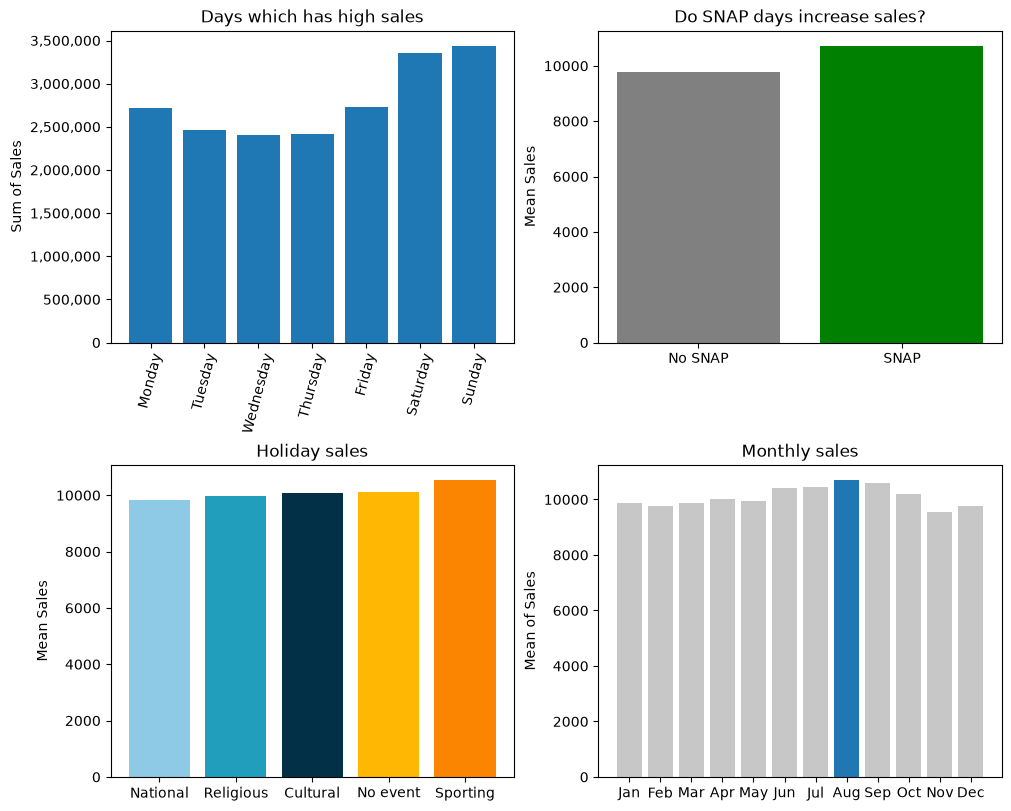

In [5]:
# Create a 2x2 grid with a 10x8 inch canvas
fig, axs = plt.subplots(2, 2, figsize=(10, 8), layout="constrained")

# 1	Which days of the week sell the most?
days_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
sum_sales_by_day  = df_open.groupby(df_open['date'].dt.day_name())['sales'].sum().reindex(days_order)

axs[0,0].bar(sum_sales_by_day.index, sum_sales_by_day.values)
axs[0,0].set_title("Days which has high sales")
axs[0,0].yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))
axs[0, 0].set_ylabel("Sum of Sales")
axs[0,0].tick_params(axis="x", rotation=75)

# Do SNAP (food-stamp) days increase food sales?
sum_snap_sales = df_open.groupby(['date', 'snap_CA'], as_index=False).agg(total_sales = ('sales', 'sum'))
snap_avg = sum_snap_sales.groupby("snap_CA")["total_sales"].mean()

snap_avg.index = snap_avg.index.map({0: "No SNAP", 1: "SNAP"})
axs[0,1].bar(snap_avg.index, snap_avg.values, color=["grey", "green"])
axs[0,1].set_title("Do SNAP days increase sales?")
axs[0,1].set_ylabel("Mean Sales")

# Which holidays or events raise or lower sales?
event_type = df_open["event_type_1"].fillna("No event")

event_sales = df_open.groupby([df_open["date"], event_type])['sales'].sum()
event_avg = event_sales.groupby(level=1).mean().sort_values()

axs[1,0].bar(event_avg.index, event_avg.values, color=['#8ecae6', '#219ebc', '#023047', '#ffb703', '#fb8500'])
axs[1,0].set_title("Holiday sales")
axs[1,0].set_ylabel("Mean Sales")

# Are there monthly or seasonal patterns
daily = df_open.groupby("date")["sales"].sum()
month_avg = daily.groupby(daily.index.month).mean()
month_avg.index = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

colors = ["#1f77b4" if m == month_avg.idxmax() else "#c7c7c7" for m in month_avg.index]
axs[1,1].bar(month_avg.index , month_avg.values, color=colors)
axs[1,1].set_title("Monthly sales")
axs[0,0].yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))
axs[1,1].set_ylabel("Mean of Sales")

### Analysis of Phase 1

**Q1 – Weekdays:** **Saturday and Sunday sell ~40% more than mid-week** (Tue–Thu are the lowest).
→ Restock before the weekend. Model feature: `wday`.

**Q2 – SNAP days:** **SNAP days sell ~9% more** (~10,700 vs ~9,800 units/day).
→ Plan extra stock for days 1–10 of each month. Model feature: `snap_CA`.

**Q3 – Events:** **Events change sales only slightly (±5%)**. Sporting events (e.g. Super Bowl) are highest; National holidays slightly lower than normal days.
→ Events matter less than weekday or SNAP. Model feature: event type (weak).

**Q4 – Months:** **Sales peak in summer (Jun–Sep, highest in August) and dip in November**, ~12% gap between top and bottom.
→ Mild seasonality. Model feature: `month`.


### Phase 2:

- This Phase covers 4 business questions

5.	Do price cuts lead to more units sold?
6.	How different are the 4 stores?
7.	Which departments (FOODS_1/2/3) drive most of the volume?
8.  How predictable are items: steady sellers vs rare sellers?


Text(0, 0.5, 'Number of products')

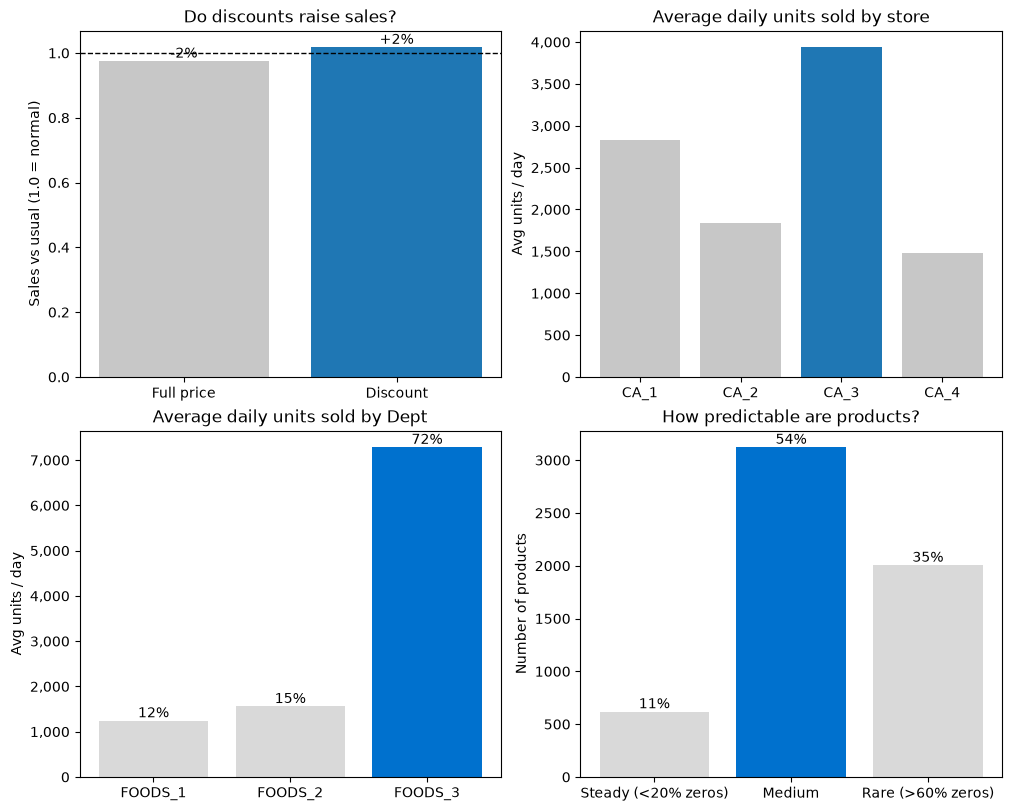

In [28]:
# Create a 2x2 grid with a 10x8 inch canvas
fig, axs = plt.subplots(2, 2, figsize=(10, 8), layout="constrained")

# Do price cuts lead to more units sold?
normal_price = df_open.groupby('id')['sell_price'].transform('max')
usual_sales  = df_open.groupby('id')['sales'].transform('mean')
on_discount  = df_open["sell_price"] < normal_price
sales_ratio  = df_open['sales'] / usual_sales
price_effect = sales_ratio.groupby(on_discount).mean()
price_effect.index = price_effect.index.map({False: "Full price", True: "Discount"})

bars = axs[0,0].bar(price_effect.index, price_effect.values, color=["#c7c7c7", "#1f77b4"])
axs[0,0].bar_label(bars, labels=[f"{(v-1)*100:+.0f}%" for v in price_effect.values])
axs[0,0].axhline(1, color="black", linestyle="--", linewidth=1)   # 1.0 = usual sales
axs[0,0].set_title("Do discounts raise sales?")
axs[0,0].set_ylabel("Sales vs usual (1.0 = normal)")

# How different 4 stores are
store_daily = df_open.groupby(["date", "store_id"])["sales"].sum()
store_avg   = store_daily.groupby(level=1).mean()

colors = ["#1f77b4" if s == store_avg.idxmax() else "#c7c7c7" for s in store_avg.index]
axs[0,1].bar(store_avg.index, store_avg.values, color=colors)
axs[0,1].set_title("Average daily units sold by store")
axs[0,1].set_ylabel("Avg units / day")
axs[0,1].yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))

# Which dept of FOODS drive sales
dept_daily = df_open.groupby(["date", "dept_id"])["sales"].sum()
dept_avg   = dept_daily.groupby(level=1).mean()

colors = ["#0071CE" if s == dept_avg.idxmax() else "#d9d9d9" for s in dept_avg.index]
bars = axs[1,0].bar(dept_avg.index, dept_avg.values, color=colors)
share = dept_avg / dept_avg.sum() * 100
axs[1,0].bar_label(bars, labels=[f"{p:.0f}%" for p in share])
axs[1,0].set_title("Average daily units sold by Dept")
axs[1,0].set_ylabel("Avg units / day")
axs[1,0].yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))

# How predictable are items: steady sellers vs rare sellers?
zero_share = (df_open["sales"] == 0).groupby(df_open["id"]).mean()
seller_type = pd.cut(zero_share, bins=[-0.01, 0.20, 0.60, 1.0], labels=["Steady (<20% zeros)", "Medium", "Rare (>60% zeros)"])
type_counts = seller_type.value_counts().reindex(seller_type.cat.categories)

colors = ["#0071CE" if t == type_counts.idxmax() else "#d9d9d9" for t in type_counts.index]
bars = axs[1,1].bar(type_counts.index, type_counts.values, color=colors)
axs[1,1].bar_label(bars, labels=[f"{v/type_counts.sum()*100:.0f}%" for v in type_counts.values])
axs[1,1].set_title("How predictable are products?")
axs[1,1].set_ylabel("Number of products")

### Analysis of Phase 2

**Q5 – Price cuts:** **Discounts lift sales only slightly**: ~2% above usual vs ~2% below at full price (~4% gap).
→ Price matters, but far less than weekday or SNAP. Model feature: price vs the item's normal price (weak–medium).

**Q6 – Stores:** **CA_3 is the busiest store (~3,900 units/day), ~2.7× CA_4 (~1,500).** Order: CA_3 > CA_1 > CA_2 > CA_4.
→ Restock volumes must be set per store. Model feature: `store_id` (strong).

**Q7 – Departments:** **FOODS_3 drives 72% of all units**; FOODS_1 (12%) and FOODS_2 (15%) are small.
→ Forecast accuracy on FOODS_3 matters most for the business. Model feature: `dept_id`.

**Q8 – Predictability:** **Only 11% of products sell steadily; 35% are rare sellers (zero sales on >60% of days).**
→ Most items are hard to predict day by day.

## Summary: EDA findings

### Business answers
| # | Question | Answer |
|---|---|---|
| 1 | Busiest days? | Weekends sell ~40% more than mid-week |
| 2 | SNAP days? | ~9% higher sales on SNAP days (days 1–10 of each month) |
| 3 | Events? | Small effect (±5%); Sporting highest, National slightly lower |
| 4 | Seasonality? | Mild: peak in Aug, low in Nov (~12% gap) |
| 5 | Price cuts? | Weak lift (~4% gap; partly price inflation over time) |
| 6 | Stores? | CA_3 busiest (~3,900/day), ~2.7× CA_4 |
| 7 | Departments? | FOODS_3 = 72% of units |
| 8 | Predictability? | Only 11% steady sellers; 35% rare (>60% zero days) |